In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
df = pd.read_csv('data/listings.csv.gz')
len(df)

4961

In [3]:
df.columns

Index(['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name',
       'description', 'neighborhood_overview', 'picture_url', 'host_id',
       'host_url', 'host_profile_id', 'host_profile_url', 'host_name',
       'host_since', 'hosts_time_as_user_years', 'hosts_time_as_user_months',
       'hosts_time_as_host_years', 'hosts_time_as_host_months',
       'host_location', 'host_about', 'host_response_time',
       'host_response_rate', 'host_acceptance_rate', 'host_is_superhost',
       'host_thumbnail_url', 'host_picture_url', 'host_neighbourhood',
       'host_listings_count', 'host_total_listings_count',
       'host_verifications', 'host_has_profile_pic', 'host_identity_verified',
       'neighbourhood', 'neighbourhood_cleansed',
       'neighbourhood_group_cleansed', 'latitude', 'longitude',
       'property_type', 'room_type', 'accommodates', 'bathrooms',
       'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price',
       'price_quote_checkin_date', 'price_quote_c

In [4]:
df.head().T

,0,1,2,3,4
id,1434108413206019816,1613802572207908117,1674132228660847237,43057420,43057598
listing_url,https://www.airbnb.com/rooms/1434108413206019816,https://www.airbnb.com/rooms/1613802572207908117,https://www.airbnb.com/rooms/1674132228660847237,https://www.airbnb.com/rooms/43057420,https://www.airbnb.com/rooms/43057598
scrape_id,20260922161643,20260922161643,20260922161643,20260922161643,20260922161643
last_scraped,2026-09-24,2026-09-24,2026-09-24,2026-09-24,2026-09-24
source,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...
calculated_host_listings_count,1,212,1,13,13
calculated_host_listings_count_entire_homes,1,211,1,13,13
calculated_host_listings_count_private_rooms,0,1,0,0,0
calculated_host_listings_count_shared_rooms,0,0,0,0,0


In [5]:
to_drop = []
checked_cols = []

Check the missing values

In [6]:
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

neighborhood_overview           4961
host_since                      4961
host_acceptance_rate            4961
host_response_rate              4961
host_response_time              4961
host_total_listings_count       4961
host_neighbourhood              4961
host_verifications              4961
host_thumbnail_url              4961
calendar_updated                4961
bathrooms                       4961
neighbourhood_group_cleansed    4961
neighbourhood                   4961
instant_bookable                4961
source                          4526
host_about                      2750
host_location                   1855
first_review                     571
reviews_per_month                571
review_scores_checkin            571
review_scores_accuracy           571
review_scores_rating             571
review_scores_cleanliness        571
review_scores_communication      571
review_scores_location           571
review_scores_value              571
last_review                      571
e

Delete data with empty or almost empty columns  

In [7]:
columns_empty = missing[missing > len(df)*0.9].index
df = df.drop(columns=columns_empty)
len(df)

4961

In [8]:
columns_empty

Index(['source', 'neighborhood_overview', 'host_since', 'host_response_time',
       'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url',
       'host_neighbourhood', 'host_total_listings_count', 'host_verifications',
       'neighbourhood', 'neighbourhood_group_cleansed', 'bathrooms',
       'calendar_updated', 'instant_bookable'],
      dtype='str')

Delete data with missing price

In [9]:
df = df.drop(df[df.price.isnull()].index)
len(df)

4627

In [10]:
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

host_about                     2544
host_location                  1717
review_scores_communication     501
review_scores_location          501
first_review                    501
review_scores_rating            501
last_review                     501
reviews_per_month               501
review_scores_value             501
review_scores_cleanliness       501
review_scores_accuracy          501
review_scores_checkin           501
license                          93
beds                             47
has_availability                  6
minimum_minimum_nights            3
maximum_minimum_nights            3
minimum_nights                    3
maximum_nights                    3
minimum_maximum_nights            3
maximum_maximum_nights            3
bathrooms_text                    1
description                       1
dtype: int64

Delete some unfinished offers. First to check if it the same raws

In [11]:
cols = missing[missing == 3].index
df[cols].isnull().any(axis=1).sum()

np.int64(3)

In [12]:
df = df.dropna(subset=cols)
len(df)

4624

Dropping the raw with bathrom description missing

In [13]:
df = df.drop(df[df.bathrooms_text.isnull()].index)
len(df)

4623

Analyse whats left

In [14]:
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

host_about                     2541
host_location                  1716
last_review                     501
first_review                    501
review_scores_rating            501
review_scores_checkin           501
review_scores_cleanliness       501
review_scores_accuracy          501
review_scores_location          501
review_scores_value             501
reviews_per_month               501
review_scores_communication     501
license                          92
beds                             47
has_availability                  6
description                       1
dtype: int64

In [15]:
df['host_location'].value_counts()

host_location
Thessaloniki, Greece      2410
Greece                      96
Athens, Greece              56
Heraklion, Greece           39
London, United Kingdom      24
                          ... 
Israel                       1
Paris, France                1
Strasbourg, France           1
Cologne, Germany             1
Nicosia, Cyprus              1
Name: count, Length: 121, dtype: int64

Feature engineering

1. Host location (categories)

In [16]:
def host_location_category(loc): 
    if pd.isna(loc): 
        return 'unknown' 
    if 'Thessaloniki' in loc: 
        return 'thessaloniki' 
    if'Greece' in loc: 
        return 'greece'
    return 'abroad' 
    
df['host_location_cat'] = df['host_location'].apply(host_location_category) 

In [17]:
df['host_location_cat'].value_counts()

host_location_cat
thessaloniki    2410
unknown         1716
greece           372
abroad           125
Name: count, dtype: int64

In [18]:
to_drop.append('host_location')

2. Reviews
   a) make a new column 'has_reviews'
   b) 'reviews_per_month    ' fill with 0

In [19]:
def has_reviews_category(loc): 
    if loc == 0: 
        return 0 
    return 1 
    
df['has_reviews'] = df['number_of_reviews'].apply(has_reviews_category) 

In [20]:
df['has_reviews'].value_counts()

has_reviews
1    4122
0     501
Name: count, dtype: int64

In [21]:
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

After splitting to fill all reviews columns with median

In [22]:
checked_cols.append('has_reviews')
checked_cols.append('reviews_per_month')

In [23]:
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

host_about                     2541
host_location                  1716
last_review                     501
first_review                    501
review_scores_cleanliness       501
review_scores_accuracy          501
review_scores_rating            501
review_scores_communication     501
review_scores_location          501
review_scores_value             501
review_scores_checkin           501
license                          92
beds                             47
has_availability                  6
description                       1
dtype: int64

3. License

In [24]:
df['license'].value_counts()

license
Exempt              36
0933Κ13000111100    15
0933Κ13000118900    15
0933Κ13000125400    11
1037314             10
                    ..
00003955113          1
36234670000          1
0933Κ13000130600     1
00003652492          1
00003941335          1
Name: count, Length: 4244, dtype: int64

In [25]:
def license_ok(loc): 
    if pd.isna(loc): 
        return 0
    return 1 
    
df['license_ok'] = df['license'].apply(license_ok) 

In [26]:
df['license_ok'].value_counts()

license_ok
1    4531
0      92
Name: count, dtype: int64

In [27]:
checked_cols.append('license_ok')
to_drop.append('license')

In [28]:
df['has_availability'].value_counts()

has_availability
t    4617
Name: count, dtype: int64

Delete non unique columns

In [29]:
df.nunique().sort_values(ascending=True)

scrape_id                    1
has_availability             1
host_has_profile_pic         2
last_scraped                 2
host_identity_verified       2
                          ... 
license                   4244
name                      4552
picture_url               4574
id                        4623
listing_url               4623
Length: 78, dtype: int64

In [30]:
nunique = df.nunique()
columns_nonunique = nunique[nunique == 1].index
df = df.drop(columns=columns_nonunique)

Cleaning price

In [31]:
df['price'].head()

0    $96.60
1    $40.00
2    $60.00
3    $94.00
4    $94.00
Name: price, dtype: str

In [32]:
df['price'] = df['price'].str.replace('$', '')
df['price'] = df['price'].str.replace(',', '')

df.price = pd.to_numeric(df.price)
df.price.head()

0    96.6
1    40.0
2    60.0
3    94.0
4    94.0
Name: price, dtype: float64

Cleaning dates (new columns - to count how many days from the first review and from the last, the days will be counted from the last scraped date)

In [33]:
df.columns

Index(['id', 'listing_url', 'last_scraped', 'name', 'description',
       'picture_url', 'host_id', 'host_url', 'host_profile_id',
       'host_profile_url', 'host_name', 'hosts_time_as_user_years',
       'hosts_time_as_user_months', 'hosts_time_as_host_years',
       'hosts_time_as_host_months', 'host_location', 'host_about',
       'host_is_superhost', 'host_picture_url', 'host_listings_count',
       'host_has_profile_pic', 'host_identity_verified',
       'neighbourhood_cleansed', 'latitude', 'longitude', 'property_type',
       'room_type', 'accommodates', 'bathrooms_text', 'bedrooms', 'beds',
       'amenities', 'price', 'price_quote_checkin_date',
       'price_quote_checkout_date', 'price_quote_total_price',
       'price_quote_price_per_night', 'price_quote_raw', 'minimum_nights',
       'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights',
       'minimum_maximum_nights', 'maximum_maximum_nights',
       'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'av

In [34]:
df['days_since_last_review'] = (pd.to_datetime(df.last_scraped) - pd.to_datetime(df.last_review)).dt.days
df['days_since_last_review'].isnull().sum()

np.int64(501)

In [35]:
df['days_since_first_review'] = (pd.to_datetime(df.last_scraped) - pd.to_datetime(df.first_review)).dt.days
df['days_since_first_review'].isnull().sum()

np.int64(501)

In [36]:
to_drop.append('last_scraped')
to_drop.append('last_review')
to_drop.append('first_review')
checked_cols.append('days_since_first_review')
checked_cols.append('days_since_last_review')

EDA

Analyse price

In [37]:
df['price'].describe()

count     4623.000000
mean       100.878890
std        259.006708
min         18.290000
25%         63.000000
50%         80.000000
75%        108.000000
max      12021.500000
Name: price, dtype: float64

<Axes: xlabel='price', ylabel='Count'>

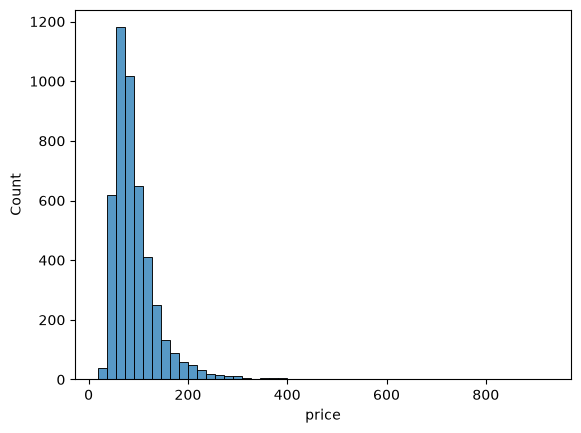

In [38]:
sns.histplot(df.price[df.price < 1000], bins=50)

In [39]:
df.price[df.price > 1000]

135      1651.00
790     12021.50
1477     5776.50
2979     2316.27
4242    10700.50
4294     1157.00
Name: price, dtype: float64

Delete prices > 1000. 2 prices about 10000 euros are clearly placeholders; values above 1000 euros look unrealistic for Thesaloniki

In [40]:
df = df.drop(df[df.price > 1000].index)
len(df)

4617

In [41]:
df['price'].skew()

np.float64(4.696697731902987)

Check if it looks like real adv (from 500 and up)

In [42]:
pd.set_option('display.max_colwidth', 200)
df[df.price > 500].description

233                       Next to the Rotunda, Rock n' Roll 1 is a unique apartment. With unique aesthetics and decoration, fully equipped, in the city center, next to all the great monuments of Thessaloniki
234         Rock n Roll 2 is a unique apartment next to the Rotunda.  In a very central location, a fully equipped house with unique aesthetics and decoration. Next to all the great monuments of Thessaloniki
1036                                                                                                                                          The apartment has modern decoration, has a fully equipped kitchen
1078    The apartment has 1 large bedroom with a double bed, a living room with two sofas where one becomes a comfortable bed, a fully equipped kitchen, a bathroom,  and a small room with a single bed. Th...
1112    This flat 130 sq.m. is located in the most desirable place of Thessaloniki between Aristotelous square and White Tower. <br />It consists of a large living area

Apply log

In [43]:
df['log_price'] = np.log1p(df['price'])
df['log_price'].skew()

np.float64(0.7727375662648258)

<Axes: xlabel='log_price', ylabel='Count'>

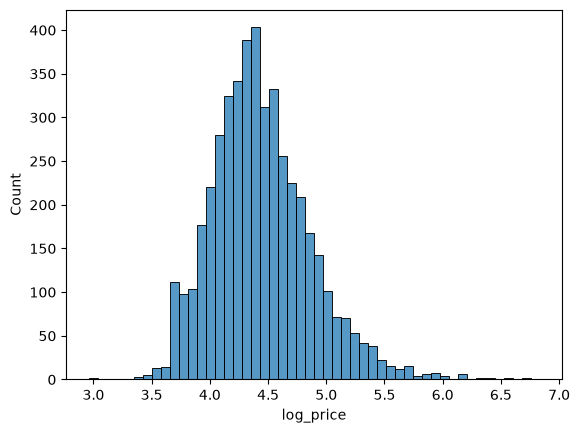

In [44]:
sns.histplot(df.log_price, bins=50)

Skew of Price: 4.69
Skew of Log Price: 0.77
After the log transformation, skewness dropped from 4.69 to 0.77(moderate), so the model will be trained on log_price

Working with batrooms categories. 87% of listing have exactly 1 bath, so creating only  2 new flags - Bathroom numbers (1 if more then 1, 0 if 1 or less) and Shared bathroom (=1 if shared)

In [45]:
df['bathrooms_text'].value_counts()

bathrooms_text
1 bath               4040
1.5 baths             227
2 baths               183
1 private bath        108
1 shared bath          14
0 baths                11
3 baths                10
2.5 baths               9
Half-bath               7
2 shared baths          2
0 shared baths          2
1.5 shared baths        1
4 baths                 1
5 baths                 1
Private half-bath       1
Name: count, dtype: int64

In [46]:
df['bathrooms_num'] = df['bathrooms_text'].str.extract(r'(\d+\.?\d*)')[0].astype(float)
df['bathrooms_num'] = df['bathrooms_num'].fillna(0.5)
df['bathrooms_num'] = (df['bathrooms_num'] > 1).astype(int)
df['bathrooms_num'].sum()

np.int64(434)

In [47]:
df['bathrooms_shared'] = df['bathrooms_text'].str.contains('shared', case=False).astype(int)
df['bathrooms_shared'].sum()
to_drop.append('bathrooms_text')

In [48]:
checked_cols.append('bathrooms_shared')
checked_cols.append('bathrooms_num')

Checking numerical columns (+ separate all 'id' columns)

In [49]:
numerical_cols = df.select_dtypes(include='number').columns
numerical_cols

Index(['id', 'host_id', 'host_profile_id', 'hosts_time_as_user_years',
       'hosts_time_as_user_months', 'hosts_time_as_host_years',
       'hosts_time_as_host_months', 'host_listings_count', 'latitude',
       'longitude', 'accommodates', 'bedrooms', 'beds', 'price',
       'price_quote_total_price', 'price_quote_price_per_night',
       'minimum_nights', 'maximum_nights', 'minimum_minimum_nights',
       'maximum_minimum_nights', 'minimum_maximum_nights',
       'maximum_maximum_nights', 'minimum_nights_avg_ntm',
       'maximum_nights_avg_ntm', 'availability_30', 'availability_60',
       'availability_90', 'availability_365', 'number_of_reviews',
       'number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy',
       'number_of_reviews_ly', 'estimated_occupancy_l365d',
       'estimated_revenue_l365d', 'review_scores_rating',
       'review_scores_accuracy', 'review_scores_cleanliness',
       'review_scores_checkin', 'review_scores_communication',
       'review_sco

Remove from numerical columns all checked, all with id and all with prices

In [50]:
id_cols = [c for c in numerical_cols if c == 'id' or c.endswith('_id')]
numerical_cols = [c for c in numerical_cols if c not in id_cols  and c not in checked_cols and 'price' not in c]
to_drop.append('estimated_revenue_l365d')

In [51]:
len(numerical_cols)

40

In [52]:
def checking_num_col(s): 
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    outliners = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
    max_share = (s.dropna() == s.max()).mean()
    skew = s.skew()
    null_quant = s.isnull().sum()
    negative_quant = (s < 0).sum()
    result = {'outliners': outliners, 'max_share': max_share, 'skew': skew, 'negative': negative_quant, 'isnull': null_quant}
    return result 

In [53]:
results = {col: checking_num_col(df[col]) for col in numerical_cols}
summary = pd.DataFrame(results).T

Checking skew

In [54]:
summary.sort_values('skew', ascending=False)

,outliners,max_share,skew,negative,isnull
minimum_minimum_nights,166.0,0.000217,31.121473,0.0,0.0
minimum_nights,166.0,0.000217,31.121473,0.0,0.0
minimum_nights_avg_ntm,311.0,0.000217,26.736613,0.0,0.0
maximum_minimum_nights,134.0,0.000217,24.991777,0.0,0.0
calculated_host_listings_count_shared_rooms,8.0,0.001733,23.968730,0.0,0.0
calculated_host_listings_count_private_rooms,496.0,0.004332,7.621078,0.0,0.0
host_listings_count,780.0,0.000217,5.179999,0.0,0.0
number_of_reviews,416.0,0.000217,4.247249,0.0,0.0
calculated_host_listings_count,711.0,0.043102,2.751235,0.0,0.0
calculated_host_listings_count_entire_homes,711.0,0.043102,2.747198,0.0,0.0


In [55]:
(df['minimum_nights']>30).sum()

np.int64(17)

Delete 17 advs because its long term renting 

In [56]:
df = df[df['minimum_nights'] <= 30]

In [57]:
results = {col: checking_num_col(df[col]) for col in numerical_cols}
summary = pd.DataFrame(results).T

In [58]:
summary.sort_values('skew', ascending=True)

,outliners,max_share,skew,negative,isnull
review_scores_checkin,336.0,0.310857,-6.403948,0.0,492.0
review_scores_communication,371.0,0.345424,-6.331529,0.0,492.0
review_scores_accuracy,294.0,0.259981,-5.006632,0.0,492.0
review_scores_cleanliness,297.0,0.270448,-4.167566,0.0,492.0
review_scores_value,293.0,0.176972,-4.035284,0.0,492.0
review_scores_rating,289.0,0.245375,-4.010280,0.0,492.0
review_scores_location,208.0,0.223953,-3.781313,0.0,492.0
availability_eoy,415.0,0.048913,-1.238572,0.0,0.0
availability_90,414.0,0.068478,-1.231103,0.0,0.0
latitude,732.0,0.000217,-1.205046,0.0,0.0


In [59]:
df['calculated_host_listings_count_shared_rooms'].value_counts()

calculated_host_listings_count_shared_rooms
0    4592
1       8
Name: count, dtype: int64

The column calculated_host_listings_count_shared_rooms to drop because only 8 non-zero values

In [60]:
to_drop.append('calculated_host_listings_count_shared_rooms')

All other skew values < 10, we will decide later to aplly log for Linear Regression

Checking negative and null values

In [61]:
summary.sort_values('negative', ascending=True)

,outliners,max_share,skew,negative,isnull
hosts_time_as_user_years,0.0,0.000217,0.015918,0.0,0.0
hosts_time_as_user_months,0.0,0.095435,0.039599,0.0,0.0
hosts_time_as_host_years,13.0,0.002826,0.318598,0.0,0.0
hosts_time_as_host_months,0.0,0.084565,0.237553,0.0,0.0
host_listings_count,780.0,0.000217,5.171393,0.0,0.0
latitude,732.0,0.000217,-1.205046,0.0,0.0
longitude,165.0,0.000217,1.690377,0.0,0.0
accommodates,196.0,0.001304,1.740135,0.0,0.0
bedrooms,47.0,0.000217,1.195473,0.0,0.0
beds,368.0,0.000439,2.486911,0.0,47.0


In [62]:
summary.sort_values('isnull', ascending=False)

,outliners,max_share,skew,negative,isnull
review_scores_value,293.0,0.176972,-4.035284,0.0,492.0
review_scores_accuracy,294.0,0.259981,-5.006632,0.0,492.0
review_scores_rating,289.0,0.245375,-4.010280,0.0,492.0
review_scores_cleanliness,297.0,0.270448,-4.167566,0.0,492.0
review_scores_communication,371.0,0.345424,-6.331529,0.0,492.0
review_scores_location,208.0,0.223953,-3.781313,0.0,492.0
review_scores_checkin,336.0,0.310857,-6.403948,0.0,492.0
beds,368.0,0.000439,2.486911,0.0,47.0
accommodates,196.0,0.001304,1.740135,0.0,0.0
longitude,165.0,0.000217,1.690377,0.0,0.0


we already know about 492 nulls in reviews, will be filled with median after splitting

Checking max share (manual check for all columns > 5%)

In [63]:
summary.sort_values('max_share', ascending=False)

,outliners,max_share,skew,negative,isnull
maximum_maximum_nights,0.0,0.359565,0.299789,0.0,0.0
maximum_nights,0.0,0.359565,0.299789,0.0,0.0
maximum_nights_avg_ntm,0.0,0.345870,0.317408,0.0,0.0
minimum_maximum_nights,0.0,0.345870,0.348288,0.0,0.0
review_scores_communication,371.0,0.345424,-6.331529,0.0,492.0
review_scores_checkin,336.0,0.310857,-6.403948,0.0,492.0
review_scores_cleanliness,297.0,0.270448,-4.167566,0.0,492.0
review_scores_accuracy,294.0,0.259981,-5.006632,0.0,492.0
review_scores_rating,289.0,0.245375,-4.010280,0.0,492.0
review_scores_location,208.0,0.223953,-3.781313,0.0,492.0


Adding to the Drop list all columns witn 'nights' exept 'minimum_nights' because other have around the same skew and outliners

In [64]:
night_cols = [c for c in df.columns if 'nights' in c and c != 'minimum_nights']
to_drop.extend(night_cols)

In [65]:
df['review_scores_communication'].sort_values(ascending=False)

15      5.0
4957    5.0
4943    5.0
4938    5.0
4933    5.0
       ... 
4955    NaN
4956    NaN
4958    NaN
4959    NaN
4960    NaN
Name: review_scores_communication, Length: 4600, dtype: float64

In [66]:
df['review_scores_checkin'].sort_values(ascending=False)

14      5.0
4908    5.0
4912    5.0
4915    5.0
4916    5.0
       ... 
4955    NaN
4956    NaN
4958    NaN
4959    NaN
4960    NaN
Name: review_scores_checkin, Length: 4600, dtype: float64

All reviews columns are normal, all have values from 1 to 5. NaN we will fill later. 

In [67]:
df['hosts_time_as_user_years'].sort_values(ascending=False)

603     16
736     15
2840    15
643     15
644     15
        ..
4902     0
75       0
4845     0
4849     0
4854     0
Name: hosts_time_as_user_years, Length: 4600, dtype: int64

We will agregate 4 columns in 2, counting in month time as user and host anf drop 4 old columns

In [68]:
df['host_tenure_month'] = df['hosts_time_as_host_months'] + df['hosts_time_as_host_years'] * 12
df['user_tenure_month'] = df['hosts_time_as_user_months'] + df['hosts_time_as_user_years'] * 12
host_user_columns = [c for c in df.columns if 'hosts_time_as_' in c]
to_drop.extend(host_user_columns)

In [69]:
df['availability_90'].sort_values(ascending=False)

1462    90
1449    90
1450    90
1446    90
1513    90
        ..
96       0
4848     0
61       0
1461     0
4930     0
Name: availability_90, Length: 4600, dtype: int64

In [70]:
df['estimated_occupancy_l365d'].sort_values(ascending=False)

47      255
2317    255
2944    255
791     255
2442    255
       ... 
4909      0
4910      0
4913      0
4917      0
4919      0
Name: estimated_occupancy_l365d, Length: 4600, dtype: int64

'estimated_occupancy_l365d' derived from review counts with Inside Airbnb’s own assumptions; duplicates existing review features 

In [71]:
to_drop.append('estimated_occupancy_l365d')
len(to_drop)

20

Make the list to fill NaN values with median after splitting

In [72]:
to_fill_median = summary[summary['isnull'] > 0].index.tolist()

Drop all columns we dont need

In [73]:
to_drop.extend(id_cols)
df =  df.drop(columns=to_drop)
df.columns

Index(['listing_url', 'name', 'description', 'picture_url', 'host_url',
       'host_profile_url', 'host_name', 'host_about', 'host_is_superhost',
       'host_picture_url', 'host_listings_count', 'host_has_profile_pic',
       'host_identity_verified', 'neighbourhood_cleansed', 'latitude',
       'longitude', 'property_type', 'room_type', 'accommodates', 'bedrooms',
       'beds', 'amenities', 'price', 'price_quote_checkin_date',
       'price_quote_checkout_date', 'price_quote_total_price',
       'price_quote_price_per_night', 'price_quote_raw', 'minimum_nights',
       'availability_30', 'availability_60', 'availability_90',
       'availability_365', 'calendar_last_scraped', 'number_of_reviews',
       'number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy',
       'number_of_reviews_ly', 'review_scores_rating',
       'review_scores_accuracy', 'review_scores_cleanliness',
       'review_scores_checkin', 'review_scores_communication',
       'review_scores_location',

Checking correlation with price

In [74]:
numerical_cols = df.select_dtypes(include='number').columns
numerical_cols = [c for c in numerical_cols if 'price' not in c]

In [75]:
df[numerical_cols].corrwith(df.log_price).abs().sort_values(ascending=False)

bedrooms                                        0.495684
accommodates                                    0.441038
beds                                            0.379204
bathrooms_num                                   0.322069
calculated_host_listings_count_entire_homes     0.257219
calculated_host_listings_count                  0.256889
review_scores_location                          0.210655
review_scores_rating                            0.194495
number_of_reviews_ly                            0.188129
review_scores_cleanliness                       0.176412
number_of_reviews_ltm                           0.168808
review_scores_accuracy                          0.158264
number_of_reviews                               0.150610
review_scores_value                             0.150585
latitude                                        0.142192
reviews_per_month                               0.142084
review_scores_communication                     0.115641
number_of_reviews_l30d         

no single numeric feature strongly predicts price (max correlation 0.49 with accommodates); price depends on a combination of features 

In [76]:
pairs = []
for col in numerical_cols:
    others = [c for c in numerical_cols if c != col]
    c = df[others].corrwith(df[col])
    strong = c[c.abs() > 0.8]
    for name, value in strong.items(): 
        pairs.append((col, name, value)) 
pd.DataFrame(pairs, columns=['feature', 'with', 'corr']) 


,feature,with,corr
0,availability_30,availability_60,0.905201
1,availability_30,availability_90,0.801574
2,availability_60,availability_30,0.905201
3,availability_60,availability_90,0.957955
4,availability_60,availability_eoy,0.943364
5,availability_90,availability_30,0.801574
6,availability_90,availability_60,0.957955
7,availability_90,availability_eoy,0.994359
8,number_of_reviews_ltm,number_of_reviews_ly,0.800812
9,number_of_reviews_ltm,reviews_per_month,0.843617


Because of high correlation between themselves removing extra features

In [77]:
availability_cols = [c for c in df.columns if 'availability_' in c and c != 'availability_90']
reviews_cols = [c for c in df.columns if 'review_scores_' in c or 'number_of_reviews_l' in c 
                and c != 'review_scores_rating' and c != 'review_scores_location']
to_drop = ['calculated_host_listings_count_entire_homes']
to_drop.extend(availability_cols)
to_drop.extend(reviews_cols)

In [78]:
df =  df.drop(columns=to_drop)
df.columns

Index(['listing_url', 'name', 'description', 'picture_url', 'host_url',
       'host_profile_url', 'host_name', 'host_about', 'host_is_superhost',
       'host_picture_url', 'host_listings_count', 'host_has_profile_pic',
       'host_identity_verified', 'neighbourhood_cleansed', 'latitude',
       'longitude', 'property_type', 'room_type', 'accommodates', 'bedrooms',
       'beds', 'amenities', 'price', 'price_quote_checkin_date',
       'price_quote_checkout_date', 'price_quote_total_price',
       'price_quote_price_per_night', 'price_quote_raw', 'minimum_nights',
       'availability_90', 'calendar_last_scraped', 'number_of_reviews',
       'calculated_host_listings_count',
       'calculated_host_listings_count_private_rooms', 'reviews_per_month',
       'host_location_cat', 'has_reviews', 'license_ok',
       'days_since_last_review', 'days_since_first_review', 'log_price',
       'bathrooms_num', 'bathrooms_shared', 'host_tenure_month',
       'user_tenure_month'],
      dtype='s

Drop all extra prices from categories as well

In [79]:
to_drop = [c for c in df.columns if c.startswith('price_quote')]
df =  df.drop(columns=to_drop)

In [80]:
categorical_cols = df.select_dtypes(exclude='number').columns.tolist()
categorical_cols

['listing_url',
 'name',
 'description',
 'picture_url',
 'host_url',
 'host_profile_url',
 'host_name',
 'host_about',
 'host_is_superhost',
 'host_picture_url',
 'host_has_profile_pic',
 'host_identity_verified',
 'neighbourhood_cleansed',
 'property_type',
 'room_type',
 'amenities',
 'calendar_last_scraped',
 'host_location_cat']

In [81]:
df.amenities

0                                                                                                              ["Air conditioning", "Smoking allowed", "Kitchen", "Outdoor dining area", "Dedicated workspace"]
1                                                                                                                                                       ["TV", "Air conditioning", "Wifi", "Washer", "Kitchen"]
2                                                                                                                                  ["TV", "Fire extinguisher", "Air conditioning", "Wifi", "Washer", "Kitchen"]
3       ["Smoke alarm", "Hair dryer", "Carbon monoxide alarm", "TV", "Heating", "Air conditioning", "Exterior security cameras on property", "Hangers", "Shampoo", "Wifi", "Self check-in", "Kitchen", "Keyp...
4       ["Smoke alarm", "Hair dryer", "Carbon monoxide alarm", "TV", "Heating", "Air conditioning", "Exterior security cameras on property", "Hangers", "Shampoo", "Wifi